# Intelligent Agents: Reflex-Based Agents for GridHunt (Multi-agent Environment)

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Apply core AI concepts by implementing the agent function for a simple and model-based reflex agents that respond to environmental percepts.
* Practice how the environment and the agent function interact.
* Analyze agent performance through controlled experiments across different environment configurations.

## Instructions

Total Points: 10

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook.
### AI Use

Here are some guidelines that will make it easier for you:

* __Don't:__ Rely on AI auto completion. You will waste a lot of time trying to figure out how the suggested code relates to what we do in class. Turn off AI code completion (e.g., Copilot) in your IDE.
* __Don't:__ Do not submit code/text that you do not understand or have not checked to make sure that it is complete and correct.
* __Do:__ Use AI for debugging and letting it explain code and concepts from class.

## Introduction

![GridHunt Image](gridhunt.png)

Gridhunt is a small educational game that helps you practice implementing simple agent functions. It is a modified Python reimplementation of Gridhunt2. 

The objective of gridhunt is to implement an intelligent agent, the hunter, who can catch a monster faster than all other hunters. Gridhunt uses a $n \times n$ arena consisting of a grid of tiles. Gridhunt is a turn-based game, and several hunter agents and the monster agent move around in the arena. A hunter catches the monster if she/he moves on the same square the monster currently occupies. The hunters compete fow who catches the monster first. If the monster survives the maximum number of steps for the game, then the monster wins.

## PEAS Description of Gridhunt

__Performance Measure:__ The performance is measured as the number of steps the hunter uses to catch the monster. Catching the monster means to be on the same square.

__Environment:__ An arena with $n \times n$ squares. At the beginning the monster and the hunters are randomly placed in the arena environment. The hunters and the monster
    can move around, but cannot leave the arena. Since there are three agents involved, this is a competitive multi-agent environment.

__Actuators:__ The agent can move to an adjacent square using actions "north", "east", "west", and "south", or teleport which will move the agent 
    to a random square in the arena.

__Sensors:__ The agent can always see its location in the arena and the location of the monster.  

## The Arena Environment

The environment manages the location of the agents (hunter and monster). It initially places them in a random location and then provides them in every step with percepts (the location of the hunter and the monster) and asks them for their action. 

__A Note on positions:__
The arena is implemented as an array with row and column indices representing the position.
Positions are stored in a numpy array where `pos[0]` is the row index and `pos[1]` is the column index in the arena. North means up in this array, that is the row index gets smaller when going north. Remember indices in Python start with 0 and go to `n-1`.

In [1]:
import numpy as np
from IPython.display import clear_output
from time import sleep

def arena_environment(hunter_1_agent_function, hunter_2_agent_function, monster_agent_function, n = 30, max_steps = 100, visualize = False, animation = False):
    """
    Simulate an arena where two hunter agent tries to catch a monster agent.

    Parameters:
    hunter_1_agent_function and hunter_2_agent_function (function): A function that takes the current positions of the hunter and monster
                                      and returns the next move for the hunter ('north', 'east', 'west', 'south', 'teleport').
    monster_agent_function (function): A function that takes the current positions of the hunter and monster
                                       and returns the next move for the monster (or 'stay' to remain in place).
    n (int): The size of the arena (n x n grid).
    max_steps (int): The maximum number of steps to simulate.
    visualize (bool): Whether to visualize the arena.
    animation (bool): Whether to animate the visualization with a delay.

    Returns:
    int: The number of steps taken for the hunter to catch the monster or np.nan (not a number) if not caught.
    """
    
    # Initialize positions
    monster_pos = np.random.randint(0, n - 1, size=2)
    hunter_1_pos = np.random.randint(0, n - 1, size=2)
    while np.array_equal(hunter_1_pos, monster_pos):
        hunter_1_pos = np.random.randint(0, n - 1, size=2)
    hunter_2_pos = np.random.randint(0, n - 1, size=2)
    while np.array_equal(hunter_2_pos, monster_pos):
        hunter_2_pos = np.random.randint(0, n - 1, size=2)    
    
    def move(action, position):
        """calculate new position for the agent."""
        if action == 'north':
            position[0] -= 1
        elif action == 'south':
            position[0] += 1
        elif action == 'west':
            position[1] -= 1
        elif action == 'east':
            position[1] += 1
        else:
            raise ValueError("Invalid action.")
        
        # Ensure position stays within bounds
        position = np.clip(position, 0, n-1)
        return position

    def print_arena():

        if animation:
            sleep(1)
            clear_output(wait=True)
        print(f"Step {step}:")
        print(f"Hunter 1 is at '{hunter_1_pos}'; Hunter 2 is at '{hunter_2_pos}'; Monster is at '{monster_pos}'\n")
        arena = np.full((n, n), '.', dtype=str)
        arena[monster_pos[0], monster_pos[1]] = 'M'
        arena[hunter_1_pos[0], hunter_1_pos[1]] = '1'
        arena[hunter_2_pos[0], hunter_2_pos[1]] = '2'
        print("\n".join("".join(row) for row in arena))

    for step in range(max_steps):
        if visualize:
            print_arena()
        
        # Check if hunter has caught the monster
        if np.array_equal(hunter_1_pos, monster_pos):
            if visualize:
                print(f"Hunter 1 caught the monster in {step} steps!")
            return ("1", step)
        
        if np.array_equal(hunter_2_pos, monster_pos):
            if visualize:
                print(f"Hunter 2 caught the monster in {step} steps!")
            return ("2", step)

        # Get next move from monster agent function
        monster_action = monster_agent_function(monster_pos, hunter_1_pos, hunter_2_pos)
        if monster_action != 'stay':
            monster_pos = move(monster_action, monster_pos)

        # Get next move from hunter agent function
        hunter_1_action = hunter_1_agent_function(hunter_1_pos, monster_pos)
        if hunter_1_action == 'teleport':
            hunter_1_pos = np.random.randint(0, n - 1, size=2)
        else:
            hunter_1_pos = move(hunter_1_action, hunter_1_pos)

        hunter_2_action = hunter_2_agent_function(hunter_2_pos, monster_pos)
        if hunter_2_action == 'teleport':
            hunter_2_pos = np.random.randint(0, n - 1, size=2)
        else:
            hunter_2_pos = move(hunter_2_action, hunter_2_pos)
    
        # print the agents' actions
        if visualize:
            print(f"Hunter 1 chose action '{hunter_1_action}'")
            print(f"Hunter 2 chose action '{hunter_2_action}'")
            print(f"Monster chose action '{monster_action}'")
            print("\n" + "="*n + "\n")

    # the hunter failed to catch the monster within max_steps
    if visualize:
        print(f"Monster won by surviving {max_steps} steps.")
    
    return ("M", np.nan)

I implement the monster here as a simple agent that moves around randomly, but mostly stays in its place. You can use AI to get a detailed explanation of how the following code works.

In [2]:
monster_actions = ["north", "east", "west", "south", "stay"]

def monster_agent_function_simple(monster_pos, hunter_1_pos, hunter_2_pos):
    return np.random.choice(monster_actions, p=[0.125, 0.125, 0.125, 0.125, 0.5])

# The Hunter Agent

Your job is to implement a simple-reflex hunter agent that can catch the monster. Remember, your agent is implemented as an agent function that get percepts and needs to return a valid action. The actions are: 

In [3]:
actions = ["north", "east", "west", "south", "teleport"]

## A Simple Example Implementation

Here is a very simple hunter that just runs around randomly and hopes that it bumps into the monster. 

In [4]:
def simple_randomized_hunter_agent_function(hunter_location, monster_location):
    return np.random.choice(actions)

Ask the agent for an action.

In [5]:
simple_randomized_hunter_agent_function([0,0], [5,5])

np.str_('north')

## Experimenting With the Agent

We can place the monster and the hunter into the environment and run a simulation by calling the environment function.

In [6]:
hunter_1 = simple_randomized_hunter_agent_function
hunter_2 = simple_randomized_hunter_agent_function

arena_environment(hunter_1, 
                  hunter_2, 
                  monster_agent_function_simple, 
                  n=5, max_steps=5, visualize=True, animation=False)

Step 0:
Hunter 1 is at '[0 0]'; Hunter 2 is at '[3 0]'; Monster is at '[3 3]'

1....
.....
.....
2..M.
.....
Hunter 1 chose action 'south'
Hunter 2 chose action 'west'
Monster chose action 'stay'

=====

Step 1:
Hunter 1 is at '[1 0]'; Hunter 2 is at '[3 0]'; Monster is at '[3 3]'

.....
1....
.....
2..M.
.....
Hunter 1 chose action 'east'
Hunter 2 chose action 'south'
Monster chose action 'stay'

=====

Step 2:
Hunter 1 is at '[1 1]'; Hunter 2 is at '[4 0]'; Monster is at '[3 3]'

.....
.1...
.....
...M.
2....
Hunter 1 chose action 'south'
Hunter 2 chose action 'south'
Monster chose action 'stay'

=====

Step 3:
Hunter 1 is at '[2 1]'; Hunter 2 is at '[4 0]'; Monster is at '[3 3]'

.....
.....
.1...
...M.
2....
Hunter 1 chose action 'south'
Hunter 2 chose action 'west'
Monster chose action 'stay'

=====

Step 4:
Hunter 1 is at '[3 1]'; Hunter 2 is at '[4 0]'; Monster is at '[3 3]'

.....
.....
.....
.1.M.
2....
Hunter 1 chose action 'west'
Hunter 2 chose action 'east'
Monster chose ac

('M', nan)

Well, this was one run, maybe it was just good or bad luck this time!

Let's run an experiment with 100 runs in a $20 \times 20$ arena.  

In [7]:
hunter_1 = simple_randomized_hunter_agent_function
hunter_2 = simple_randomized_hunter_agent_function

steps = [arena_environment(hunter_1, 
                           hunter_2, 
                           monster_agent_function_simple, 
                           n=20, max_steps=100, visualize=False) for _ in range(100)] 
print(steps)

[('2', 48), ('2', 8), ('M', nan), ('2', 84), ('M', nan), ('M', nan), ('M', nan), ('2', 18), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('1', 61), ('M', nan), ('M', nan), ('M', nan), ('1', 7), ('2', 65), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('2', 42), ('M', nan), ('2', 55), ('1', 35), ('M', nan), ('M', nan), ('2', 2), ('M', nan), ('M', nan), ('2', 14), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('1', 90), ('M', nan), ('M', nan), ('M', nan), ('1', 68), ('M', nan), ('1', 94), ('1', 3), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('2', 24), ('2', 89), ('M', nan), ('M', nan), ('M', nan), ('1', 21), ('M', nan), ('M', nan), ('1', 23), ('2', 3), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('2', 1), ('1', 22), ('1', 52), ('2', 10), ('1', 1), ('M', nan), ('2', 98), ('1', 45), ('M', nan), ('M', nan), ('M', nan), ('2', 45), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('M', nan), ('1

We just got a list with who one and the number of steps to catch the monster for 100 simulation runs.
Let's analysis the results by counting who won how often.

In [8]:
steps = np.array(steps)

print (f"Hunter 1 won: {np.sum(steps[:,0] == "1")}")
print (f"Hunter 2 won: {np.sum(steps[:,0] == "2")}")
print (f"Monster 1 won: {np.sum(steps[:,0] == "M")}")       


Hunter 1 won: 17
Hunter 2 won: 19
Monster 1 won: 64


The random agent in not a very good hunter. You need to implement a better agent function.

# Your Agent Implementation [4 points]

Write a new hunter agent function that chases the monster. Copy the simple randomized hunter function from above and modify it using rules based on the monster's and the hunter's location. Let your hunter compete with the random agent. You can also come up with several different agents and let them compete against each other.

In [9]:
# here goes your agent implementation
# actions = ["north", "east", "west", "south", "teleport"]
def greedy_hunter(hunter_location, monster_location):
    hunter_row, hunter_col = hunter_location
    monster_row, monster_col = monster_location

    if hunter_row < monster_row:
        return "south"
    if hunter_row > monster_row:
        return "north"
    if hunter_col < monster_col:
        return "east"
    if hunter_col > monster_col:
        return "west"
    
    return "teleport"

def teleport_hunter(hunter_location, monster_location):
    hunter_row, hunter_col = hunter_location
    monster_row, monster_col = monster_location

    threshold = 5
    if abs(hunter_col - monster_col) < threshold and abs(hunter_row - monster_row) < threshold:
        if hunter_row < monster_row:
            return "south"
        if hunter_row > monster_row:
            return "north"
        if hunter_col < monster_col:
            return "east"
        if hunter_col > monster_col:
            return "west"
    
    return "teleport"

# Your Experiments [2 points]

Copy the simulation code from above and run experiments with your agent. 
Experiment with larger arenas of at least size $30 \times 30$.

In [18]:
# Your experimentation code goes here
hunter_1 = greedy_hunter
hunter_2 = teleport_hunter

steps = [arena_environment(hunter_1, 
                           hunter_2, 
                           monster_agent_function_simple, 
                           n=30, max_steps=100, visualize=False) for _ in range(100)] 
print(steps)

[('1', 29), ('1', 4), ('2', 15), ('2', 24), ('1', 7), ('2', 8), ('1', 28), ('1', 14), ('2', 16), ('2', 38), ('1', 9), ('2', 10), ('2', 5), ('2', 16), ('2', 11), ('2', 29), ('2', 14), ('2', 6), ('1', 16), ('2', 34), ('1', 10), ('2', 3), ('2', 5), ('2', 22), ('2', 32), ('2', 5), ('2', 2), ('2', 9), ('2', 29), ('1', 13), ('1', 20), ('1', 11), ('1', 15), ('1', 16), ('1', 7), ('2', 19), ('2', 14), ('2', 4), ('2', 74), ('2', 15), ('2', 55), ('1', 21), ('2', 7), ('2', 9), ('1', 3), ('1', 12), ('1', 26), ('2', 16), ('1', 26), ('1', 11), ('1', 16), ('2', 14), ('2', 16), ('1', 5), ('1', 17), ('2', 12), ('2', 14), ('1', 49), ('2', 3), ('1', 17), ('2', 24), ('1', 24), ('2', 11), ('1', 8), ('2', 41), ('1', 26), ('1', 15), ('2', 14), ('2', 11), ('2', 12), ('1', 22), ('2', 8), ('2', 9), ('2', 25), ('2', 15), ('2', 2), ('2', 15), ('1', 29), ('2', 11), ('2', 13), ('2', 10), ('2', 3), ('1', 16), ('1', 14), ('2', 12), ('2', 23), ('1', 10), ('2', 6), ('2', 15), ('1', 7), ('2', 6), ('1', 6), ('1', 34), ('2

In [19]:
steps = np.array(steps)

print (f"Hunter 1 won: {np.sum(steps[:,0] == "1")}")
print (f"Hunter 2 won: {np.sum(steps[:,0] == "2")}")
print (f"Monster 1 won: {np.sum(steps[:,0] == "M")}")       


Hunter 1 won: 40
Hunter 2 won: 60
Monster 1 won: 0


## Your Conclusion [4 points] 

Discuss the following:

* What is your hunter's final strategy to choose actions. Why does it work well?
* Do you use teleportation. Why and in what situation? Why not?
* How does the arena size affects your hunter agent's performance?

> Your discussion goes here

**What is your hunter's final strategy to choose actions. Why does it work well?**

Our team built two agents, namely *greedy hunter* and *teleport hunter* for this problem and evaluate these two to see which one works better.

**Greedy hunter**'s strategy is to gradually shorten the distance between the hunter and the monster. It's able to do that by constantly checking the position of the monster and the hunter itself using hunter's percepts, which is collected by hunter's sensors. Those percepts are then used to calculate the distance between two objects, which gives the agent more percepts to think and decide an action that actually shrinks the distance of the two objects.

**Teleport hunter** works almost similar to greedy hunter, except that once the distance between the hunter and the monster is greater than a threshold, the agent will automatically use the teleport actuator, which helps the agent to get random position on the arena. In some cases, teleport actuator could help agent shrink the distance with the monster, which is a huge advantage. We don't choose to use teleportation too often as it could lead to the worst case where the gap between the agent and the monster could be increased.

When it comes to effectiveness comparison between these two hunters approach, we usually see the teleport hunter has more effective than the other. But as the arena size gets bigger and bigger, the effectiveness of these two agents are nearly the same, at some point the teleport hunter's effectiveness is lower than the other agent, and eventually it comes to the point where the monster just win most of the runs.

<img src="gridhunt_hunter_win_rate.png" width=900>

The monster is also an agent. Describe how the monster's agent function could be changed so it gets better at avoiding the hunter.

> Your discussion goes here

The monster could be better at avoiding hunters by being more unpredictable when moving. For now, the probability of the monster to stay at the old position is 50%, which makes it predictable. The probability distribution should be adjusted to help the monster more difficult to be beaten.

# More Work (optional)

* Improve the monster agent so it tries to run away from the hunters. Don;t make the monster too fast or the hunters will never be able to catch it.
* How could the two hunter agents work together? You need to think about information sharing. This can be implemented by the two agent functions sharing a single Python class or the environment could be expanded by an action "shout" that lets the other agent perceive a message.

In [ ]:
"""AI Generated: Code dùng để chạy thực nghiệm 2 chiến thuật hunter trên các kích cỡ khác nhau của arena"""
# Benchmark greedy_hunter vs teleport_hunter and save visualization-ready data.
from csv import DictWriter
from pathlib import Path
from time import perf_counter

def benchmark_hunters(grid_sizes, runs=100, max_steps=100, seed=42, output_file="gridhunt_hunter_benchmark.csv"):
    """Run repeated games and write one aggregate row per grid size."""
    np.random.seed(seed)
    rows = []

    for n in grid_sizes:
        started_at = perf_counter()
        winners = []
        capture_steps = {"1": [], "2": []}

        for _ in range(runs):
            winner, steps = arena_environment(
                greedy_hunter,
                teleport_hunter,
                monster_agent_function_simple,
                n=n,
                max_steps=max_steps,
                visualize=False,
            )
            winners.append(winner)
            if winner in capture_steps:
                capture_steps[winner].append(steps)

        elapsed_seconds = perf_counter() - started_at
        hunter_1_wins = winners.count("1")
        hunter_2_wins = winners.count("2")
        monster_wins = winners.count("M")
        rows.append({
            "grid_size": n,
            "runs": runs,
            "max_steps": max_steps,
            "seed": seed,
            "total_runtime_seconds": round(elapsed_seconds, 6),
            "mean_runtime_ms_per_game": round(elapsed_seconds * 1000 / runs, 6),
            "hunter_1_greedy_wins": hunter_1_wins,
            "hunter_2_teleport_wins": hunter_2_wins,
            "monster_wins": monster_wins,
            "hunter_1_win_rate": round(hunter_1_wins / runs, 4),
            "hunter_2_win_rate": round(hunter_2_wins / runs, 4),
            "monster_win_rate": round(monster_wins / runs, 4),
            "mean_steps_when_hunter_1_wins": round(float(np.mean(capture_steps["1"])), 4) if capture_steps["1"] else None,
            "mean_steps_when_hunter_2_wins": round(float(np.mean(capture_steps["2"])), 4) if capture_steps["2"] else None,
        })

    output_path = Path(output_file)
    with output_path.open("w", newline="", encoding="utf-8") as csv_file:
        writer = DictWriter(csv_file, fieldnames=rows[0].keys())
        writer.writeheader()
        writer.writerows(rows)

    return rows, output_path.resolve()

# Mỗi lần tăng grid thêm 10: 10x10, 20x20, ..., 1000x1000.
grid_sizes = list(range(10, 1001, 10))
benchmark_rows, csv_path = benchmark_hunters(grid_sizes, runs=100, max_steps=100)
print(f"Saved benchmark results to: {csv_path}")
benchmark_rows


Saved benchmark results to: /home/thien408/Projects/2026-2027/ai_advanced/ML-Advance-Group/lab01/lab01 - Agent/gridhunt_hunter_benchmark.csv


[{'grid_size': 10,
  'runs': 100,
  'max_steps': 100,
  'seed': 42,
  'total_runtime_seconds': 0.015071,
  'mean_runtime_ms_per_game': 0.150708,
  'hunter_1_greedy_wins': 41,
  'hunter_2_teleport_wins': 59,
  'monster_wins': 0,
  'hunter_1_win_rate': 0.41,
  'hunter_2_win_rate': 0.59,
  'monster_win_rate': 0.0,
  'mean_steps_when_hunter_1_wins': 5.4878,
  'mean_steps_when_hunter_2_wins': 5.1864},
 {'grid_size': 20,
  'runs': 100,
  'max_steps': 100,
  'seed': 42,
  'total_runtime_seconds': 0.033944,
  'mean_runtime_ms_per_game': 0.339442,
  'hunter_1_greedy_wins': 28,
  'hunter_2_teleport_wins': 72,
  'monster_wins': 0,
  'hunter_1_win_rate': 0.28,
  'hunter_2_win_rate': 0.72,
  'monster_win_rate': 0.0,
  'mean_steps_when_hunter_1_wins': 10.5357,
  'mean_steps_when_hunter_2_wins': 7.9861},
 {'grid_size': 30,
  'runs': 100,
  'max_steps': 100,
  'seed': 42,
  'total_runtime_seconds': 0.048619,
  'mean_runtime_ms_per_game': 0.486187,
  'hunter_1_greedy_wins': 48,
  'hunter_2_teleport_win

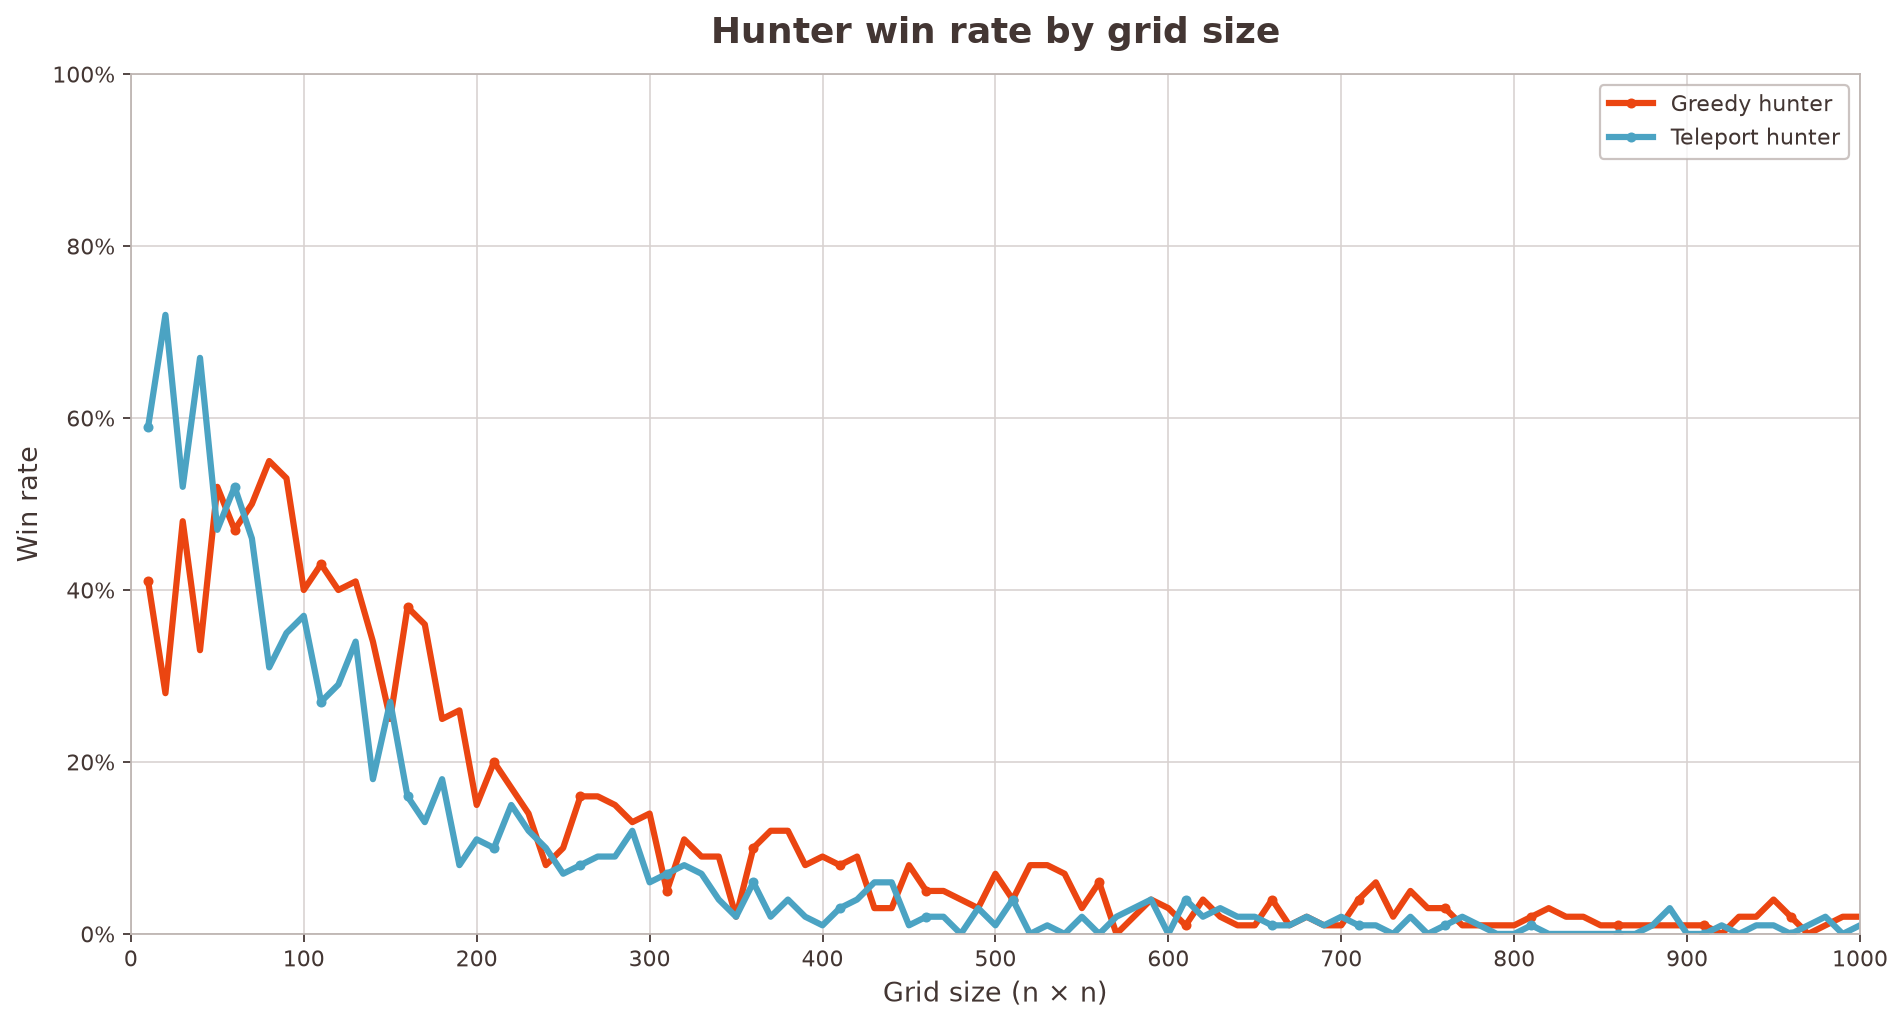

Saved line graph to: /home/thien408/Projects/2026-2027/ai_advanced/ML-Advance-Group/lab01/lab01 - Agent/gridhunt_hunter_win_rate.png


In [ ]:
"""AI Generated: Trực quan hóa dữ liệu sau khi chạy thực nghiệm"""
# Line graph: win rate of greedy_hunter vs teleport_hunter.
from csv import DictReader
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Use csv_path from the benchmark cell when available.
benchmark_csv = Path(csv_path) if "csv_path" in globals() else Path("gridhunt_hunter_benchmark.csv")
with benchmark_csv.open(encoding="utf-8") as csv_file:
    benchmark_data = list(DictReader(csv_file))

grid_sizes = [int(row["grid_size"]) for row in benchmark_data]
greedy_win_rates = [float(row["hunter_1_win_rate"]) for row in benchmark_data]
teleport_win_rates = [float(row["hunter_2_win_rate"]) for row in benchmark_data]

# Palette inspired by the supplied colors.
GREEDY_ORANGE = "#EB4511"
TELEPORT_TURQUOISE = "#4BA3C3"
MOCHA = "#433633"
GRID_GRAY = "#D8D2D0"

fig, ax = plt.subplots(figsize=(12, 6.5), dpi=160)
fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#FFFFFF")

ax.plot(
    grid_sizes, greedy_win_rates,
    label="Greedy hunter", color=GREEDY_ORANGE,
    linewidth=2.8, marker="o", markersize=3.5, markevery=5,
)
ax.plot(
    grid_sizes, teleport_win_rates,
    label="Teleport hunter", color=TELEPORT_TURQUOISE,
    linewidth=2.8, marker="o", markersize=3.5, markevery=5,
)

ax.set_title("Hunter win rate by grid size", fontsize=16, fontweight="bold", color=MOCHA, pad=14)
ax.set_xlabel("Grid size (n × n)", fontsize=12, color=MOCHA)
ax.set_ylabel("Win rate", fontsize=12, color=MOCHA)
ax.set_xlim(min(grid_sizes), max(grid_sizes))
ax.set_ylim(0, 1)
ax.set_xticks(range(0, max(grid_sizes) + 1, 100))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.grid(True, color=GRID_GRAY, linewidth=0.8, alpha=0.9)
ax.set_axisbelow(True)
ax.tick_params(colors=MOCHA)
for spine in ax.spines.values():
    spine.set_color("#BEB5B2")

legend = ax.legend(frameon=True, facecolor="#FFFFFF", edgecolor="#BEB5B2", loc="upper right")
for label in legend.get_texts():
    label.set_color(MOCHA)

fig.tight_layout()
plot_path = benchmark_csv.with_name("gridhunt_hunter_win_rate.png")
fig.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved line graph to: {plot_path.resolve()}")
